Exercit, iul 1. De la independent,ă condit, ionată la factorizare
Considerăm trei variabile aleatoare discrete A, B, C s, i graful neorientat A − B − C. Presupunem
că distribut, ia comună este strict pozitivă pentru toate configurat, iile posibile.

a) Explicat, i, în cuvintele voastre, ce înseamnă A ⊥ C | B. Ce informat, ie suplimentară despre
A mai oferă C atunci când cunoas,tem B?

b) Pornind de la formula probabilităt, ii condit, ionate, demonstrat, i că A ⊥ C | B implică existent,a
unor potent, iale strict pozitive φAB s, i φBC s, i a unei constante Z > 0 pentru care

P(a, b, c) = 1
Z
φAB(a, b)φBC(b, c).

Indiciu: folosit, i P(a, b, c) = P(a | b)P(c | b)P(b).

c) Demonstrat, i s, i reciproca, pornind de la factorizarea de mai sus. Indiciu: calculat, i P(a, c | b)
s, i verificat, i dacă este produsul lui P(a | b) s, i P(c | b).



______________________________________________________________________________________________________

a) A ⊥ C | B înseamă evenimentele A și C sunt indepentente atunci când știim informații despre evenimentul B. Din perspectiva graficului, dacă cunoașterea unui eveniment este asemănător cu eliminarea evenimentului din grafic, atunci putem observa că nodul A este deconectat de nodul C (astfel avem independența). Dacă știm evenimentul B, atunci informația C nu ne oferă nicio informație utilă despre evenimentul A

b)P(a,b,c)=(1/Z)*φAB(a, b)*φBC(b, c).

Din definiția probabilității condiționale știm că
P(a,b,c) poate fi scris ca fiind:
P(a,b,c)=P(a|b,c)*P(c|b)* P(b)<=>P(a,b,c)=P(a|b)*P(c|b)*P(b) [deoarece am demonstat că a nu este influențat de c dacă știm b]

(1/Z)*φAB(a, b)*φBC(b, c) trebuie să fie egală cu P(a|b)*P(c|b)*P(b)=P(a,b)/P(b)*P(c,b)/P(b)*P(b). Dacă presupunem că P(a,b)=φAB(a|b) și P(c|b)=φBC(b, c) și 1/Z=P(b) atunci obținem ce aveam de demonstrat.



c) P(a,c|b)=P(a,b,c)/P(b).
P(a,c|b)*P(b)=(1/Z)*φAB(a, b)*φBC(b, c). Pentru P(b)=1/Z avem:
P(a,c|b)=φAB(a, b)*φBC(b, c). Din exemplul anterior unde φAB(a, b)=P(a|b) și φBC(b, c)=P(c|b) avem că
P(a,c|b)=P(a|b)*P(c|b) care este fix formula independeței condiționale atunci când știm informații despre un eveniment.





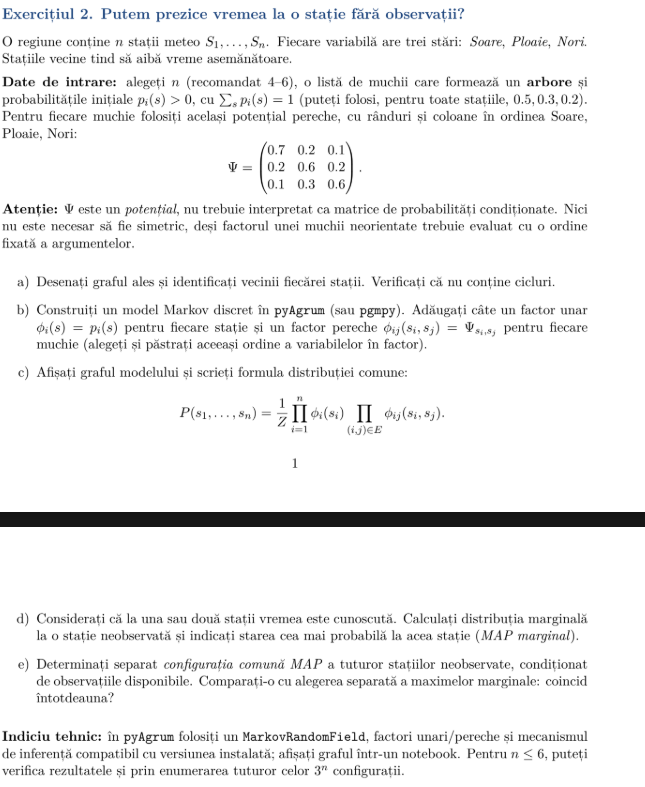

In [2]:
pip install pgmpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 52.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [pgmpy]


In [4]:
#b
from pgmpy.models import DiscreteMarkovNetwork
from pgmpy.factors.discrete import DiscreteFactor

model = DiscreteMarkovNetwork([('S1', 'S2'), ('S1', 'S3'), ('S3', 'S4'), ('S3', 'S5')])

stari = ['Soare', 'Ploaie', 'Nori']
card = 3

prob_initiale = [0.5, 0.3, 0.2]
factori_unari = []

for nod in ['S1', 'S2', 'S3', 'S4', 'S5']:
    # Factorul depinde doar de variabila nodului curent
    factor = DiscreteFactor([nod], [card], prob_initiale)
    factori_unari.append(factor)


valori_psi = [
    0.7, 0.2, 0.1,
    0.2, 0.6, 0.2,
    0.1, 0.3, 0.6
]

muchii = [('S1', 'S2'), ('S1', 'S3'), ('S3', 'S4'), ('S3', 'S5')]
factori_pereche = []

for u, v in muchii:

    factor = DiscreteFactor([u, v], [card, card], valori_psi)
    factori_pereche.append(factor)


model.add_factors(*factori_unari)
model.add_factors(*factori_pereche)


assert model.check_model() == True
print("Modelul Markov a fost construit și validat!")

Modelul Markov a fost construit și validat!


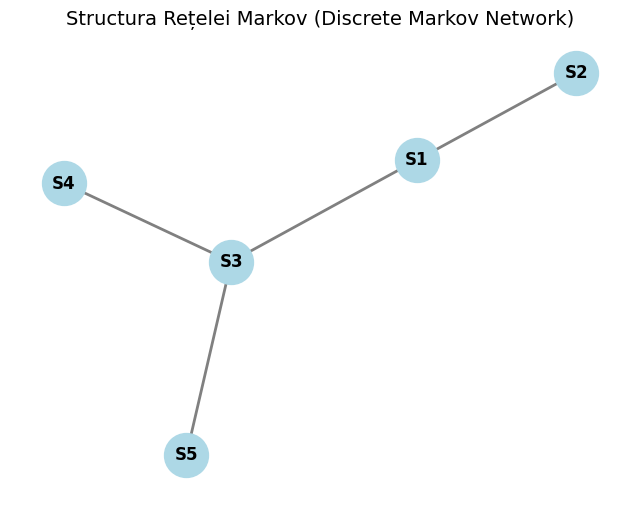

In [7]:
#a
import matplotlib.pyplot as plt
import networkx as nx

# Creăm o figură pentru desen
plt.figure(figsize=(8, 6))

# Creăm un graf networkx curat pe baza nodurilor și muchiilor din modelul pgmpy
graf_nx = nx.Graph()
graf_nx.add_nodes_from(model.nodes())
graf_nx.add_edges_from(model.edges())

# Generăm pozițiile nodurilor folosind un layout de tip spring
pos = nx.spring_layout(graf_nx, seed=42)

# Desenăm graful: nodurile, muchiile și etichetele
nx.draw_networkx_nodes(graf_nx, pos, node_size=1000, node_color='lightblue')
nx.draw_networkx_edges(graf_nx, pos, width=2, edge_color='gray')
nx.draw_networkx_labels(graf_nx, pos, font_size=12, font_family='sans-serif', font_weight='bold')

plt.title("Structura Rețelei Markov (Discrete Markov Network)", fontsize=14)
plt.axis('off')
plt.show()

In [8]:
import numpy as np
import pandas as pd
from pgmpy.inference import BeliefPropagation

# Putem folosi Belief Propagation din pgmpy pentru a calcula probabilitatea comună
inference = BeliefPropagation(model)

# Calculăm distribuția comună completă prin calibrare/interogare
# Deoarece vrem distribuția comună a tuturor variabilelor:
joint_distribution = inference.query(variables=['S1', 'S2', 'S3', 'S4', 'S5'])

print("Factorul rezultat pentru distribuția comună:")
print(joint_distribution)


/usr/local/lib/python3.13/dist-packages/pgmpy/estimators/__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


Factorul rezultat pentru distribuția comună:
+-------+-------+-------+-------+-------+-----------------------+
| S1    | S2    | S3    | S4    | S5    |   phi(S1,S2,S3,S4,S5) |
+=======+=======+=======+=======+=======+=======================+
| S1(0) | S2(0) | S3(0) | S4(0) | S5(0) |                0.3623 |
+-------+-------+-------+-------+-------+-----------------------+
| S1(0) | S2(0) | S3(0) | S4(0) | S5(1) |                0.0621 |
+-------+-------+-------+-------+-------+-----------------------+
| S1(0) | S2(0) | S3(0) | S4(0) | S5(2) |                0.0207 |
+-------+-------+-------+-------+-------+-----------------------+
| S1(0) | S2(0) | S3(0) | S4(1) | S5(0) |                0.0621 |
+-------+-------+-------+-------+-------+-----------------------+
| S1(0) | S2(0) | S3(0) | S4(1) | S5(1) |                0.0106 |
+-------+-------+-------+-------+-------+-----------------------+
| S1(0) | S2(0) | S3(0) | S4(1) | S5(2) |                0.0035 |
+-------+-------+-------+------

### Calculul Distribuției Marginale și MAP Marginal

Presupunem următorul scenariu:
* **Stații observate**: $S_1$ este cunoscută ca fiind în starea `Ploaie` (indicele `1`), iar $S_2$ este cunoscută ca fiind în starea `Soare` (indicele `0`).
* **Stație neobservată**: Ne interesează să aflăm distribuția marginală și starea cea mai probabilă (MAP) pentru stația $S_3$.

In [9]:
# Definim dovezile (evidence)
# S1 = 1 (Ploaie), S2 = 0 (Soare)
evidenta = {'S1': 1, 'S2': 0}

# Calculăm distribuția marginală pentru S3 condiționată de dovezile noastre
marginal_S3 = inference.query(variables=['S3'], evidence=evidenta)

print("Distribuția marginală pentru S3, având în vedere dovezi la S1 și S2:")
print(marginal_S3)

# Extragerea stării celei mai probabile (MAP)
valori = marginal_S3.values
stare_map_index = np.argmax(valori)
starea_map = stari[stare_map_index]

print(f"\nStarea cea mai probabilă (MAP) la stația S3 este: {starea_map} (Indice: {stare_map_index}) cu o probabilitate de {valori[stare_map_index]:.4f}")

Distribuția marginală pentru S3, având în vedere dovezi la S1 și S2:
+-------+-----------+
| S3    |   phi(S3) |
+=======+===========+
| S3(0) |    0.4666 |
+-------+-----------+
| S3(1) |    0.4651 |
+-------+-----------+
| S3(2) |    0.0682 |
+-------+-----------+

Starea cea mai probabilă (MAP) la stația S3 este: Soare (Indice: 0) cu o probabilitate de 0.4666


### Determinarea configurației comune MAP vs. Maximizare marginală separată

În această secțiune:
1. Calculăm configurația comună cea mai probabilă (MAP comun / MPE) a variabilelor neobservate $S_3, S_4, S_5$, condiționată de $S_1 = 1$ (Ploaie) și $S_2 = 0$ (Soare).
2. Calculăm independent maximele marginale pentru fiecare dintre aceste variabile.
3. Comparăm rezultatele și explicăm dacă cele două metode coincid întotdeauna.

In [11]:
# 1. Calculăm MAP-ul comun (MPE) folosind funcția map_query din pgmpy
map_comun = inference.map_query(variables=['S3', 'S4', 'S5'], evidence=evidenta)
print("Configurația comună MAP (MPE) pentru variabilele neobservate:")
for var, state_idx in map_comun.items():
    print(f"{var}: {stari[state_idx]} (Indice: {state_idx})")

# 2. Calculăm maximele marginale individuale pentru S3, S4 și S5
print("\nMaximele marginale calculate separat:")
for var in ['S3', 'S4', 'S5']:
    dist_marginala = inference.query(variables=[var], evidence=evidenta)
    valori_marginala = dist_marginala.values
    max_idx = np.argmax(valori_marginala)
    print(f"{var}: {stari[max_idx]} (Indice: {max_idx}) cu probabilitatea {valori_marginala[max_idx]:.4f}")


0it [00:00, ?it/s]

Configurația comună MAP (MPE) pentru variabilele neobservate:
S4: Soare (Indice: 0)
S5: Soare (Indice: 0)
S3: Soare (Indice: 0)

Maximele marginale calculate separat:
S3: Soare (Indice: 0) cu probabilitatea 0.4666
S4: Soare (Indice: 0) cu probabilitatea 0.5383
S5: Soare (Indice: 0) cu probabilitatea 0.5383


### Concluzie și Analiză teoretică

**Coincid întotdeauna cele două abordări?**
**Nu.** Alegerea separată a maximelor marginale și configurația comună MAP (MPE) **nu coincid întotdeauna**.

**Explicație:**
* **Maximele Marginale Separate** maximizează probabilitatea fiecărei variabile în parte, integrând (sumând) peste toate stările posibile ale celorlalte variabile: $P(S_i | e) = \sum_{S \setminus \{S_i\}} P(S | e)$. Această abordare ignoră corelațiile și dependențele strânse dintre variabilele neobservate.
* **MAP-ul Comun (MPE)** caută acea configurație globală unică a tuturor variabilelor care maximizează probabilitatea comună: $\arg\max_{S} P(S | e)$.
* Într-o rețea cu dependențe puternice (cum sunt factorii de tranziție de pe muchii), o combinație de stări marginale foarte probabile individual poate fi chiar imposibilă sau extrem de puțin probabilă la nivel global dacă acele stări sunt incompatibile sau penalizate de factorii de legătură.

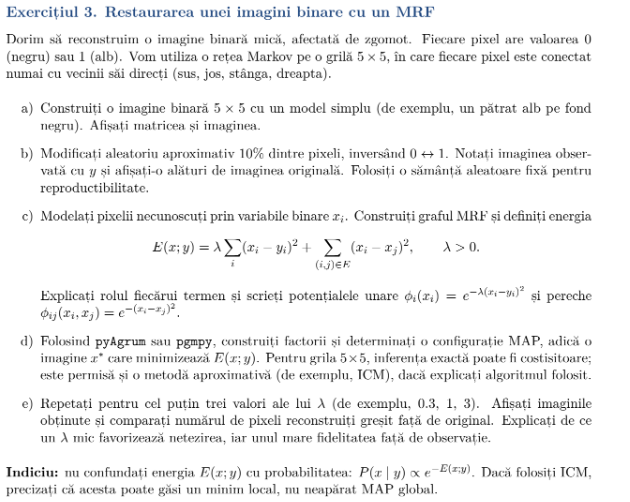
______________________________________________________________________________________________________

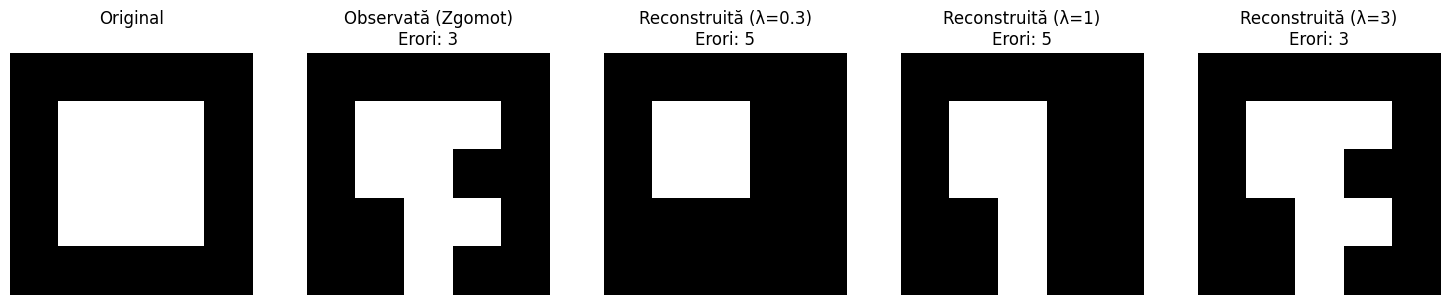

In [23]:
#3 import numpy as np
import matplotlib.pyplot as plt

# a) Construirea imaginii originale (pătrat alb 3x3 pe fond negru)
x_orig = np.zeros((5, 5), dtype=int)
x_orig[1:4, 1:4] = 1

# b) Generarea imaginii cu zgomot (inversăm aprox. 10% din pixeli)
y = x_orig.copy()
num_pixels = y.size
num_flips = int(0.1 * num_pixels) # 10% din 25 = 2.5 -> luăm 3 pixeli
flip_indices = np.random.choice(num_pixels, 3, replace=False)
y.flat[flip_indices] = 1 - y.flat[flip_indices]

# Funcție utilitară pentru vecinii direcți (sus, jos, stânga, dreapta)
def get_neighbors(i, j, rows, cols):
    neighbors = []
    if i > 0: neighbors.append((i-1, j))
    if i < rows - 1: neighbors.append((i+1, j))
    if j > 0: neighbors.append((i, j-1))
    if j < cols - 1: neighbors.append((i, j+1))
    return neighbors

# d) Algoritmul ICM pentru inferență aproximativă MAP
def icm_restore(y, lambda_val, max_iter=50):
    rows, cols = y.shape
    x = y.copy() # Inițializăm x cu observația y

    for iteration in range(max_iter):
        changed = False
        for i in range(rows):
            for j in range(cols):
                # Calculăm energia locală pentru starea 0
                e0 = lambda_val * (0 - y[i, j])**2
                for ni, nj in get_neighbors(i, j, rows, cols):
                    e0 += (0 - x[ni, nj])**2

                # Calculăm energia locală pentru starea 1
                e1 = lambda_val * (1 - y[i, j])**2
                for ni, nj in get_neighbors(i, j, rows, cols):
                    e1 += (1 - x[ni, nj])**2

                # Alegem starea care minimizează energia locală
                best_val = 0 if e0 < e1 else 1
                if x[i, j] != best_val:
                    x[i, j] = best_val
                    changed = True

        # Oprim algoritmul dacă nicio valoare nu s-a mai schimbat (minim local)
        if not changed:
            break
    return x

# e) Testarea pentru diferite valori ale lui lambda
lambdas = [0.3, 1, 3]
results = {}
errors = {}

for l in lambdas:
    restored = icm_restore(y, l)
    results[l] = restored
    errors[l] = np.sum(restored != x_orig)

# Vizualizarea rezultatelor
fig, axes = plt.subplots(1, 5, figsize=(15, 3))

axes[0].imshow(x_orig, cmap='gray', vmin=0, vmax=1)
axes[0].set_title("Original\n")
axes[0].axis('off')

axes[1].imshow(y, cmap='gray', vmin=0, vmax=1)
axes[1].set_title(f"Observată (Zgomot)\nErori: {np.sum(y != x_orig)}")
axes[1].axis('off')

for idx, l in enumerate(lambdas):
    ax = axes[idx + 2]
    ax.imshow(results[l], cmap='gray', vmin=0, vmax=1)
    ax.set_title(f"Reconstruită (λ={l})\nErori: {errors[l]}")
    ax.axis('off')

plt.tight_layout()
plt.show()